MovieWriter imagemagick unavailable; using Pillow instead.


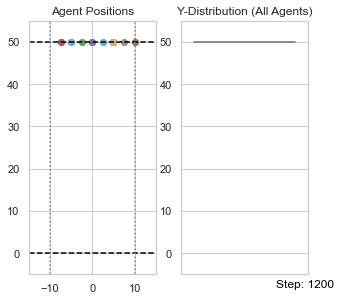

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import seaborn as sns
from matplotlib import gridspec
import random
import pandas as pd
import math

# パラメータ
n_agents = 20
n_steps = 1201
Pf = 10**-1.7
step_size = 2.5
direction_choices = [0, np.pi/2, np.pi, 3*np.pi/2]
x_grid = np.arange(-10.0, 12.5, 2.5)

#Dry parameter
Pgo, Pturn, Phtr = 0.601, 0.202, 0.0
Pstop = 1 - Pgo - Pturn - Phtr
prob_move = [Pgo, Pstop, Pturn, Phtr]

#wet parameter
Pgo_w = 0.601
Pturn_w = 0.202
Phtr_w = 0.0
Pstop_w = 1 - Pgo_w - Pturn_w - Phtr_w
prob_move_w = [Pgo_w, Pstop_w, Pturn_w, Phtr_w]

# エージェント初期化
positions = [[(np.random.choice(x_grid), 0.0)] for _ in range(n_agents)]
angles = [np.random.choice(direction_choices) for _ in range(n_agents)]
agents_state = [[1.0] for _ in range(n_agents)] #o: without water; 1: with water

field_state = [np.ones((round((50/step_size)+1), round((20/step_size)+1))) for _ in range(n_steps+1)]
#for s in range (n_steps+1):
    #field_state[s][math.floor(50/step_size)]=1.0 
#field_state[0:11]=1.0 #Wet surface

# ランダムに10個体を選抜（固定）
selected_indices = sorted(random.sample(range(n_agents), n_agents))

def turn_angle(current_angle):
    return (current_angle + np.random.choice([0, np.pi/2, -np.pi/2])) % (2 * np.pi)

def apply_boundary(i, new_x, new_y):
    if new_y >= 50:
        new_y = 50.0
    if new_y <= 0:
        new_y = 0.0
        angles[i] = np.random.choice([0, np.pi])
        agents_state[i] = 1.0
    if new_x > 10:
        new_x = -10 + (new_x - 10)
    elif new_x < -10:
        new_x = 10 - (-10 - new_x)
    return new_x, new_y

def move(i, step):
    x, y = positions[i][-1]
    fx = round(x/step_size+4)
    fy = round(50/step_size-y/step_size)
    fstate = field_state[step]
    if y == 50.0:
        action = 'stop'    
    elif fstate[fy][fx] == 0.0 and agents_state[i] == 1.0:
        agents_state[i] = 0.0
        field_state[step+1][fy][fx] = 1.0
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    elif y == 0.0:
        agents_state[i] = 1.0
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    elif fstate[fy][fx] == 1.0:
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    else:
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move)

    if action == 'stop':
        positions[i].append((x, y))
        return
    elif action == 'turn':
        angles[i] = turn_angle(angles[i])
        positions[i].append((x, y))
        return
    elif action == 'HTR':
        angles[i] = np.random.choice([np.pi/2, 3*np.pi/2])
        positions[i].append((x, y))
        if np.random.rand() < Pf:
            positions[i].append((x, 0))
            angles[i] = np.random.choice([0, np.pi])
        return

    
    dx = step_size * np.cos(angles[i])
    dy = step_size * np.sin(angles[i])
    new_x, new_y = x + dx, y + dy
    new_x, new_y = apply_boundary(i, new_x, new_y)
    new_x = round(new_x, 1)
    new_y = round(new_y, 1)
    positions[i].append((new_x, new_y))

# ===simulation===
for step in range(n_steps):
    field_state[step+1] = field_state[step]
    for i in range(n_agents):
        move(i, step)
    
# --- 描画セットアップ ---
fig = plt.figure(figsize=(5, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1])

# 左: エージェント位置表示（選抜10個体のみ）
ax_pos = plt.subplot(gs[0])
scats = [ax_pos.plot([], [], 'o')[0] for _ in selected_indices]
time_text = ax_pos.text(1.95, -0.05, '', transform=ax_pos.transAxes, fontsize=12, color='black')
ax_pos.axhline(0, color='black', linestyle='--')
ax_pos.axhline(50, color='black', linestyle='--')
ax_pos.axvline(-10, color='gray', linestyle=':')
ax_pos.axvline(10, color='gray', linestyle=':')
ax_pos.set_xlim(-15, 15)
ax_pos.set_ylim(-5, 55)
ax_pos.set_aspect('equal')
ax_pos.set_title("Agent Positions")

# 右: バイオリンプロット
ax_violin = plt.subplot(gs[1])
ax_violin.set_box_aspect(60/30)
sns.set(style="whitegrid")

# --- 更新関数 ---
def update(frame):
    # 左: 選ばれた10個体のみ表示
    for idx, agent_i in enumerate(selected_indices):
        xs, ys = zip(*positions[agent_i][:frame+1])
        scats[idx].set_data(xs[-1], ys[-1])

    # 右: 全個体のY座標分布をバイオリンプロット
    ax_violin.clear()
    y_vals = [positions[i][frame][1] for i in range(n_agents)]
    sns.violinplot(y=y_vals, orient='v', ax=ax_violin, showfliers=False, color='skyblue',cut=0 )
    ax_violin.set_ylim(-5, 55)
    ax_violin.set_xticks([])
    ax_violin.set_title("Y-Distribution (All Agents)")
    time_text.set_text(f"Step: {frame}")
    return scats + [time_text]

# アニメーション生成 & 保存
ani = FuncAnimation(fig, update, frames=range(0, n_steps, 10), interval=10, blit=False)
ani.save("WetSurface_Pf017_01.gif", writer="imagemagick")
update(n_steps - 1)
plt.show()

# 各エージェントの最終位置 y座標をまとめる
final_y_C1 = [ traj[-1][1] for traj in positions ]
final_x_C1 = [ traj[-1][0] for traj in positions ]
final_field_C1 = field_state[n_steps]


MovieWriter imagemagick unavailable; using Pillow instead.


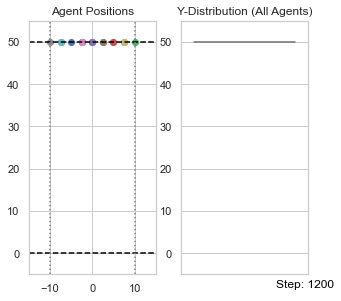

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import seaborn as sns
from matplotlib import gridspec
import random
import pandas as pd
import math

# パラメータ
n_agents = 20
n_steps = 1201
Pf = 10**-1.7
step_size = 2.5
direction_choices = [0, np.pi/2, np.pi, 3*np.pi/2]
x_grid = np.arange(-10.0, 12.5, 2.5)

#Dry parameter
Pgo, Pturn, Phtr = 0.601, 0.202, 0.0
Pstop = 1 - Pgo - Pturn - Phtr
prob_move = [Pgo, Pstop, Pturn, Phtr]

#wet parameter
Pgo_w = 0.601
Pturn_w = 0.202
Phtr_w = 0.0
Pstop_w = 1 - Pgo_w - Pturn_w - Phtr_w
prob_move_w = [Pgo_w, Pstop_w, Pturn_w, Phtr_w]

# エージェント初期化
positions = [[(np.random.choice(x_grid), 0.0)] for _ in range(n_agents)]
angles = [np.random.choice(direction_choices) for _ in range(n_agents)]
agents_state = [[1.0] for _ in range(n_agents)] #o: without water; 1: with water

field_state = [np.ones((round((50/step_size)+1), round((20/step_size)+1))) for _ in range(n_steps+1)]
#for s in range (n_steps+1):
    #field_state[s][math.floor(50/step_size)]=1.0 
#field_state[0:11]=1.0 #Wet surface

# ランダムに10個体を選抜（固定）
selected_indices = sorted(random.sample(range(n_agents), n_agents))

def turn_angle(current_angle):
    return (current_angle + np.random.choice([0, np.pi/2, -np.pi/2])) % (2 * np.pi)

def apply_boundary(i, new_x, new_y):
    if new_y >= 50:
        new_y = 50.0
    if new_y <= 0:
        new_y = 0.0
        angles[i] = np.random.choice([0, np.pi])
        agents_state[i] = 1.0
    if new_x > 10:
        new_x = -10 + (new_x - 10)
    elif new_x < -10:
        new_x = 10 - (-10 - new_x)
    return new_x, new_y

def move(i, step):
    x, y = positions[i][-1]
    fx = round(x/step_size+4)
    fy = round(50/step_size-y/step_size)
    fstate = field_state[step]
    if y == 50.0:
        action = 'stop'    
    elif fstate[fy][fx] == 0.0 and agents_state[i] == 1.0:
        agents_state[i] = 0.0
        field_state[step+1][fy][fx] = 1.0
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    elif y == 0.0:
        agents_state[i] = 1.0
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    elif fstate[fy][fx] == 1.0:
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    else:
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move)

    if action == 'stop':
        positions[i].append((x, y))
        return
    elif action == 'turn':
        angles[i] = turn_angle(angles[i])
        positions[i].append((x, y))
        return
    elif action == 'HTR':
        angles[i] = np.random.choice([np.pi/2, 3*np.pi/2])
        positions[i].append((x, y))
        if np.random.rand() < Pf:
            positions[i].append((x, 0))
            angles[i] = np.random.choice([0, np.pi])
        return

    
    dx = step_size * np.cos(angles[i])
    dy = step_size * np.sin(angles[i])
    new_x, new_y = x + dx, y + dy
    new_x, new_y = apply_boundary(i, new_x, new_y)
    new_x = round(new_x, 1)
    new_y = round(new_y, 1)
    positions[i].append((new_x, new_y))

# ===simulation===
for step in range(n_steps):
    field_state[step+1] = field_state[step]
    for i in range(n_agents):
        move(i, step)
    
# --- 描画セットアップ ---
fig = plt.figure(figsize=(5, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1])

# 左: エージェント位置表示（選抜10個体のみ）
ax_pos = plt.subplot(gs[0])
scats = [ax_pos.plot([], [], 'o')[0] for _ in selected_indices]
time_text = ax_pos.text(1.95, -0.05, '', transform=ax_pos.transAxes, fontsize=12, color='black')
ax_pos.axhline(0, color='black', linestyle='--')
ax_pos.axhline(50, color='black', linestyle='--')
ax_pos.axvline(-10, color='gray', linestyle=':')
ax_pos.axvline(10, color='gray', linestyle=':')
ax_pos.set_xlim(-15, 15)
ax_pos.set_ylim(-5, 55)
ax_pos.set_aspect('equal')
ax_pos.set_title("Agent Positions")

# 右: バイオリンプロット
ax_violin = plt.subplot(gs[1])
ax_violin.set_box_aspect(60/30)
sns.set(style="whitegrid")

# --- 更新関数 ---
def update(frame):
    # 左: 選ばれた10個体のみ表示
    for idx, agent_i in enumerate(selected_indices):
        xs, ys = zip(*positions[agent_i][:frame+1])
        scats[idx].set_data(xs[-1], ys[-1])

    # 右: 全個体のY座標分布をバイオリンプロット
    ax_violin.clear()
    y_vals = [positions[i][frame][1] for i in range(n_agents)]
    sns.violinplot(y=y_vals, orient='v', ax=ax_violin, showfliers=False, color='skyblue',cut=0 )
    ax_violin.set_ylim(-5, 55)
    ax_violin.set_xticks([])
    ax_violin.set_title("Y-Distribution (All Agents)")
    time_text.set_text(f"Step: {frame}")
    return scats + [time_text]

# アニメーション生成 & 保存
ani = FuncAnimation(fig, update, frames=range(0, n_steps, 10), interval=10, blit=False)
ani.save("WetSurface_Pf017_02.gif", writer="imagemagick")
update(n_steps - 1)
plt.show()

# 各エージェントの最終位置 y座標をまとめる
final_y_C2 = [ traj[-1][1] for traj in positions ]
final_x_C2 = [ traj[-1][0] for traj in positions ]
final_field_C2 = field_state[n_steps]


MovieWriter imagemagick unavailable; using Pillow instead.


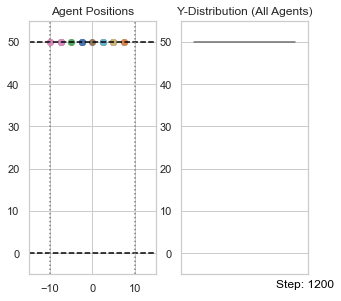

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import seaborn as sns
from matplotlib import gridspec
import random
import pandas as pd
import math

# パラメータ
n_agents = 20
n_steps = 1201
Pf = 10**-1.7
step_size = 2.5
direction_choices = [0, np.pi/2, np.pi, 3*np.pi/2]
x_grid = np.arange(-10.0, 12.5, 2.5)

#Dry parameter
Pgo, Pturn, Phtr = 0.601, 0.202, 0.0
Pstop = 1 - Pgo - Pturn - Phtr
prob_move = [Pgo, Pstop, Pturn, Phtr]

#wet parameter
Pgo_w = 0.601
Pturn_w = 0.202
Phtr_w = 0.0
Pstop_w = 1 - Pgo_w - Pturn_w - Phtr_w
prob_move_w = [Pgo_w, Pstop_w, Pturn_w, Phtr_w]

# エージェント初期化
positions = [[(np.random.choice(x_grid), 0.0)] for _ in range(n_agents)]
angles = [np.random.choice(direction_choices) for _ in range(n_agents)]
agents_state = [[1.0] for _ in range(n_agents)] #o: without water; 1: with water

field_state = [np.ones((round((50/step_size)+1), round((20/step_size)+1))) for _ in range(n_steps+1)]
#for s in range (n_steps+1):
    #field_state[s][math.floor(50/step_size)]=1.0 
#field_state[0:11]=1.0 #Wet surface

# ランダムに10個体を選抜（固定）
selected_indices = sorted(random.sample(range(n_agents), n_agents))

def turn_angle(current_angle):
    return (current_angle + np.random.choice([0, np.pi/2, -np.pi/2])) % (2 * np.pi)

def apply_boundary(i, new_x, new_y):
    if new_y >= 50:
        new_y = 50.0
    if new_y <= 0:
        new_y = 0.0
        angles[i] = np.random.choice([0, np.pi])
        agents_state[i] = 1.0
    if new_x > 10:
        new_x = -10 + (new_x - 10)
    elif new_x < -10:
        new_x = 10 - (-10 - new_x)
    return new_x, new_y

def move(i, step):
    x, y = positions[i][-1]
    fx = round(x/step_size+4)
    fy = round(50/step_size-y/step_size)
    fstate = field_state[step]
    if y == 50.0:
        action = 'stop'    
    elif fstate[fy][fx] == 0.0 and agents_state[i] == 1.0:
        agents_state[i] = 0.0
        field_state[step+1][fy][fx] = 1.0
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    elif y == 0.0:
        agents_state[i] = 1.0
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    elif fstate[fy][fx] == 1.0:
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move_w)
    else:
        action = np.random.choice(['straight', 'stop', 'turn', 'HTR'], p=prob_move)

    if action == 'stop':
        positions[i].append((x, y))
        return
    elif action == 'turn':
        angles[i] = turn_angle(angles[i])
        positions[i].append((x, y))
        return
    elif action == 'HTR':
        angles[i] = np.random.choice([np.pi/2, 3*np.pi/2])
        positions[i].append((x, y))
        if np.random.rand() < Pf:
            positions[i].append((x, 0))
            angles[i] = np.random.choice([0, np.pi])
        return

    
    dx = step_size * np.cos(angles[i])
    dy = step_size * np.sin(angles[i])
    new_x, new_y = x + dx, y + dy
    new_x, new_y = apply_boundary(i, new_x, new_y)
    new_x = round(new_x, 1)
    new_y = round(new_y, 1)
    positions[i].append((new_x, new_y))

# ===simulation===
for step in range(n_steps):
    field_state[step+1] = field_state[step]
    for i in range(n_agents):
        move(i, step)
    
# --- 描画セットアップ ---
fig = plt.figure(figsize=(5, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1])

# 左: エージェント位置表示（選抜10個体のみ）
ax_pos = plt.subplot(gs[0])
scats = [ax_pos.plot([], [], 'o')[0] for _ in selected_indices]
time_text = ax_pos.text(1.95, -0.05, '', transform=ax_pos.transAxes, fontsize=12, color='black')
ax_pos.axhline(0, color='black', linestyle='--')
ax_pos.axhline(50, color='black', linestyle='--')
ax_pos.axvline(-10, color='gray', linestyle=':')
ax_pos.axvline(10, color='gray', linestyle=':')
ax_pos.set_xlim(-15, 15)
ax_pos.set_ylim(-5, 55)
ax_pos.set_aspect('equal')
ax_pos.set_title("Agent Positions")

# 右: バイオリンプロット
ax_violin = plt.subplot(gs[1])
ax_violin.set_box_aspect(60/30)
sns.set(style="whitegrid")

# --- 更新関数 ---
def update(frame):
    # 左: 選ばれた10個体のみ表示
    for idx, agent_i in enumerate(selected_indices):
        xs, ys = zip(*positions[agent_i][:frame+1])
        scats[idx].set_data(xs[-1], ys[-1])

    # 右: 全個体のY座標分布をバイオリンプロット
    ax_violin.clear()
    y_vals = [positions[i][frame][1] for i in range(n_agents)]
    sns.violinplot(y=y_vals, orient='v', ax=ax_violin, showfliers=False, color='skyblue',cut=0 )
    ax_violin.set_ylim(-5, 55)
    ax_violin.set_xticks([])
    ax_violin.set_title("Y-Distribution (All Agents)")
    time_text.set_text(f"Step: {frame}")
    return scats + [time_text]

# アニメーション生成 & 保存
ani = FuncAnimation(fig, update, frames=range(0, n_steps, 10), interval=10, blit=False)
ani.save("WetSurface_Pf017_03.gif", writer="imagemagick")
update(n_steps - 1)
plt.show()

# 各エージェントの最終位置 y座標をまとめる
final_y_C3 = [ traj[-1][1] for traj in positions ]
final_x_C3 = [ traj[-1][0] for traj in positions ]
final_field_C3 = field_state[n_steps]


In [9]:
df_DrySurf_C = pd.DataFrame(final_y_C1+final_y_C2+final_y_C3, columns=['Control'])
df_DrySurf_D = pd.DataFrame(final_y_C1+final_y_C2+final_y_C3, columns=['Dessication'])
df_DrySurf = pd.concat([df_DrySurf_C, df_DrySurf_D],axis=1 )
df_DrySurf_melt = pd.melt(df_DrySurf)
df_DrySurf_melt

,variable,value
0,Control,50.0
1,Control,50.0
2,Control,50.0
3,Control,50.0
4,Control,50.0
...,...,...
115,Dessication,50.0
116,Dessication,50.0
117,Dessication,50.0
118,Dessication,50.0


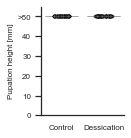

In [10]:
sns.set()
sns.set_style("ticks") # スタイルをticksに
fig = plt.figure(figsize = (1.5,2))
ax = fig.add_subplot(1, 1, 1)
sns.violinplot(x='variable', y='value', data=df_DrySurf_melt, showfliers=False, cut=0,linewidth=0.5, ax=ax)
sns.stripplot(x='variable', y='value', data=df_DrySurf_melt, jitter=1/5, marker="o",  size=3, linewidth=0.5,
              color = "#80808080", edgecolor = "black", ax=ax)

plt.ylim(0, 55)
plt.ylabel("Pupation height [mm]", size = 8)
plt.xlabel("", size = 8)
ax.tick_params(labelsize = 8, bottom=False)
ax.set_yticks([0, 10, 20, 30, 40, 50])
ax.set_yticklabels(["0", "10", "20", "30", "40", ">50"])
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(True)

plt.show()
plt.rcParams["svg.fonttype"] = "none"
fig.savefig("PSA_Simulation_WS_v1.svg")
